# 03 — Voice verification

Owner: **Kudakwashe**

This notebook builds a speaker-identity classifier from original voice recordings. It uses SpeechBrain's pretrained [ECAPA-TDNN VoxCeleb model](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb) (Apache-2.0) for speaker embeddings. MFCCs, spectral roll-off and RMS are recorded as analysis features; the classifier uses only speaker embeddings.

Every original recording is assigned to one split before pitch-shift and noise variants are created. Augmented descendants stay with their original split. Validation samples calibrate the rejection threshold; test samples, when available, are never used to select it.

**Data limitation:** this run uses two original recordings per speaker, which provide only train/validation splits and no independent test set. Validation/calibration metrics are provisional, not held-out performance. Patrick's two MP4 audio tracks decode to under 1.3 seconds each after silence trimming, and all speakers have very few recordings; results are therefore highly uncertain. Additional independent sessions are needed for testing. The unauthorized folder is currently empty, so unknown-person false-acceptance cannot be measured. This classroom model does not provide liveness or replay protection.

In [1]:
from pathlib import Path
import sys
import zlib

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "main.py").exists(), "Run from the project root or notebooks directory"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
MODELS = ROOT / "models"

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd

from feature_extraction import load_voice_audio
from voice_model import (
    augment_audio,
    build_feature_table,
    discover_recordings,
    split_original_recordings,
    train_voice_model,
)


## 1. Inventory and split original recordings

The split is by original source and speaker. Two recordings per speaker produce train/validation only; the code does not claim an independent test result.

In [2]:
recordings = discover_recordings(DATA / "raw" / "audio")
split_recordings = split_original_recordings(recordings, random_state=42)
inventory = pd.DataFrame(split_recordings)
display(inventory.groupby(["user_id", "split"], as_index=False).size())
print(f"Original recordings: {len(recordings)}; speakers: {inventory['user_id'].nunique()}")
test_speakers = set(inventory.loc[inventory["split"] == "test", "user_id"])
missing_test_speakers = sorted(set(inventory["user_id"]) - test_speakers)
if missing_test_speakers:
    print(f"Incomplete independent test coverage; missing speakers: {', '.join(missing_test_speakers)}")


,user_id,split,size
0,kudakwashe,train,1
1,kudakwashe,validation,1
2,larissa,train,1
3,larissa,validation,1
4,maurice,train,1
5,maurice,validation,1
6,patrick,train,1
7,patrick,validation,1


Original recordings: 8; speakers: 4
Incomplete independent test coverage; missing speakers: kudakwashe, larissa, maurice, patrick


## 2. Listen and inspect waveforms and spectrograms

The loader converts recordings to mono 16 kHz audio and trims leading/trailing silence at 30 dB below peak.

C:\Users\pc\multimodal_authentication_preprocessing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


kudakwashe / kudakwashe/Kudakwashe_sample_02: 1.09s at 16000 Hz


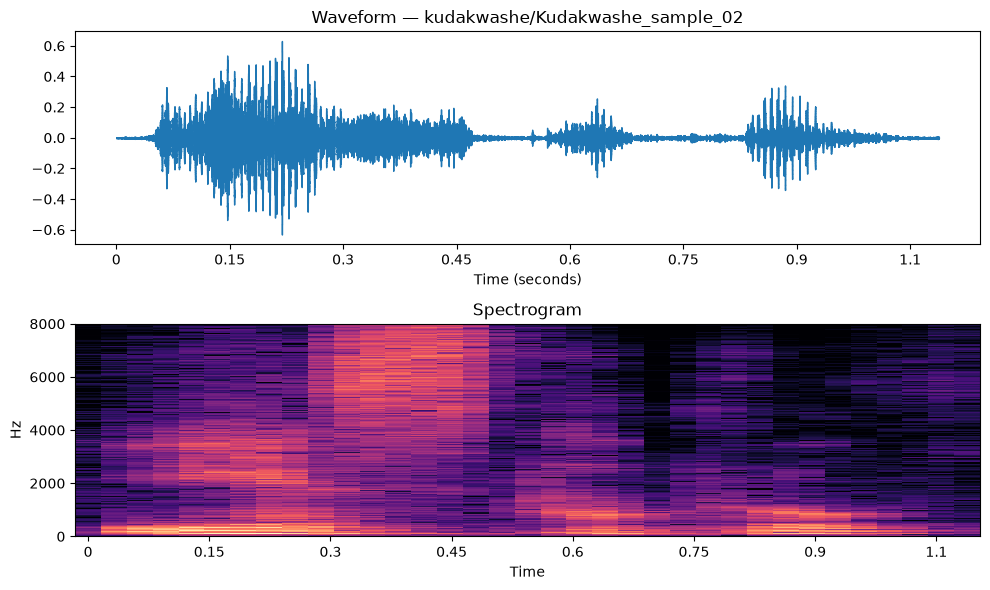

kudakwashe / kudakwashe/Kudakwashe_sample_01: 1.63s at 16000 Hz


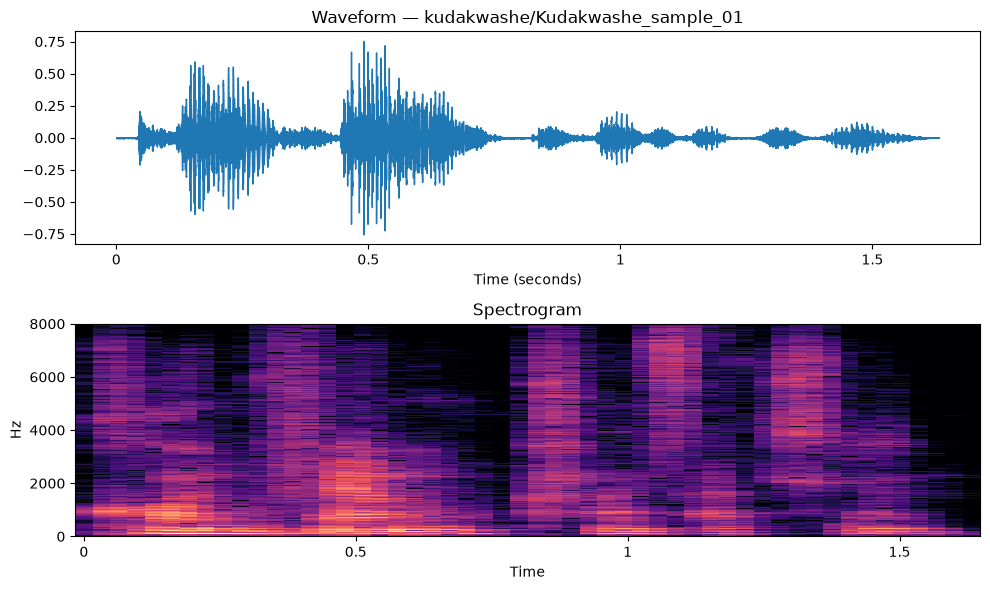

larissa / larissa/Larissa_Approved: 1.54s at 16000 Hz


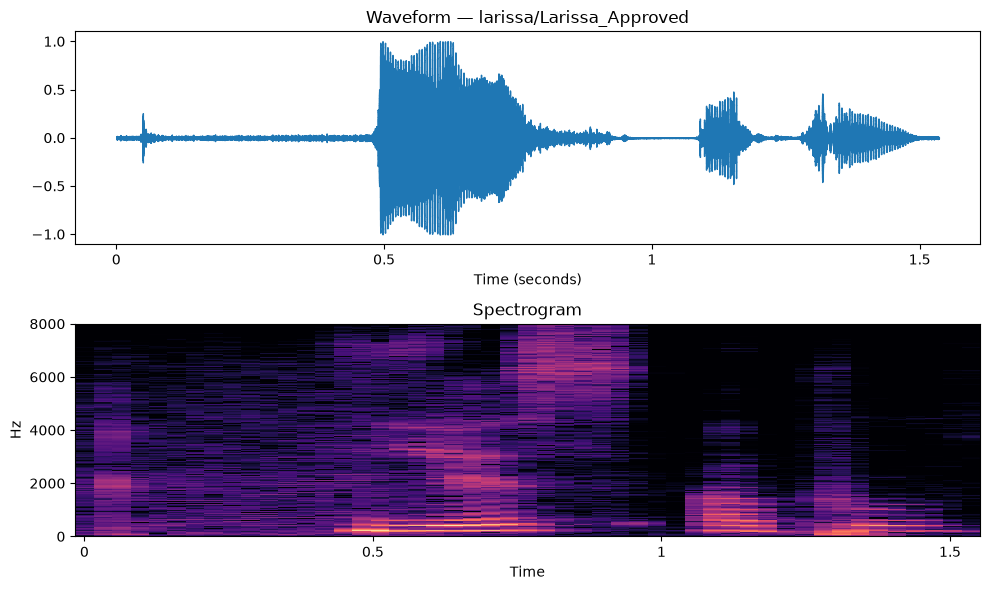

larissa / larissa/Larissa_Confirm transaction: 1.63s at 16000 Hz


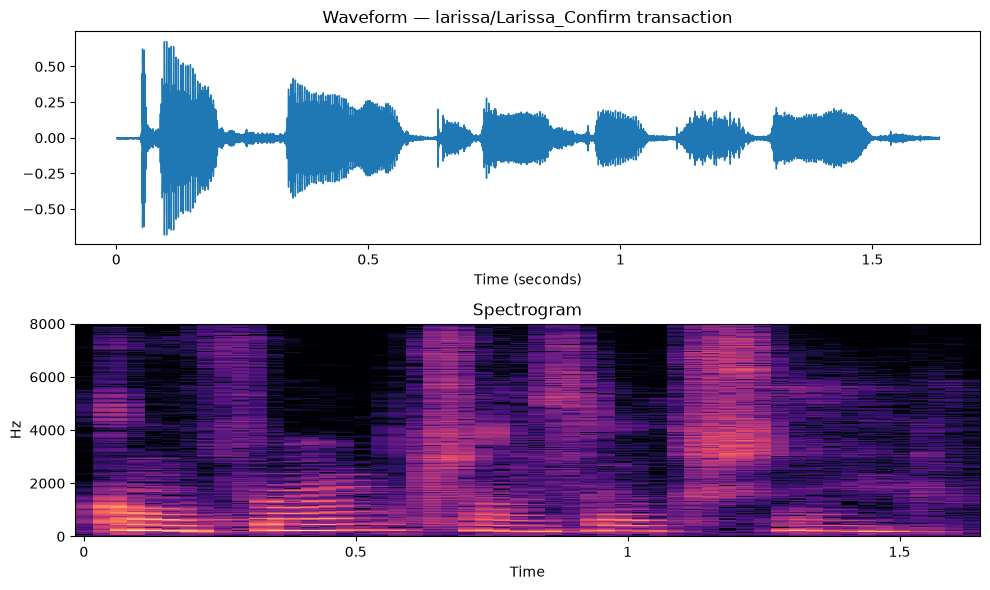

maurice / maurice/Maurice_Approved: 2.85s at 16000 Hz


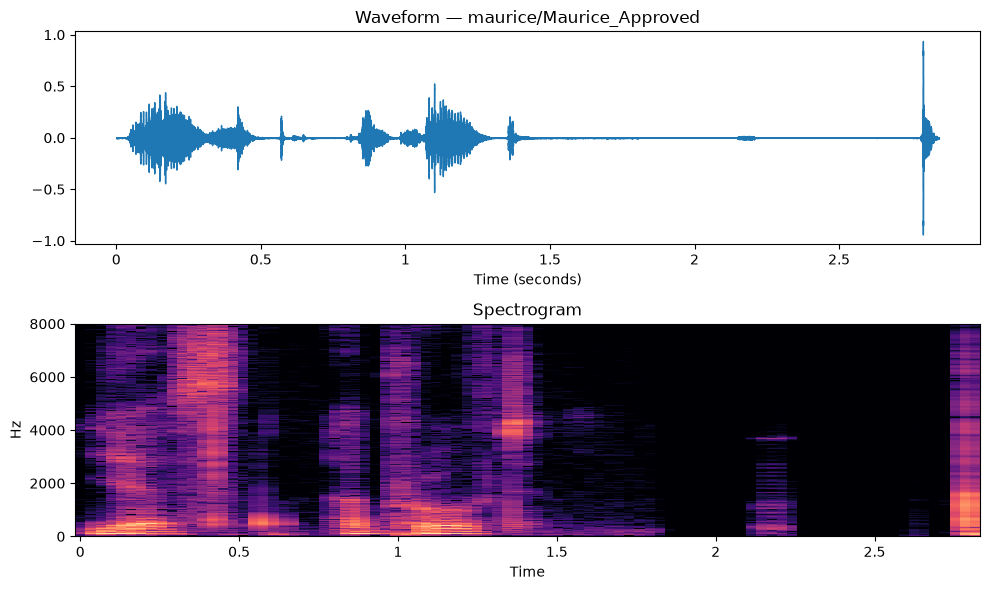

maurice / maurice/Maurice_Confirm transaction: 2.21s at 16000 Hz


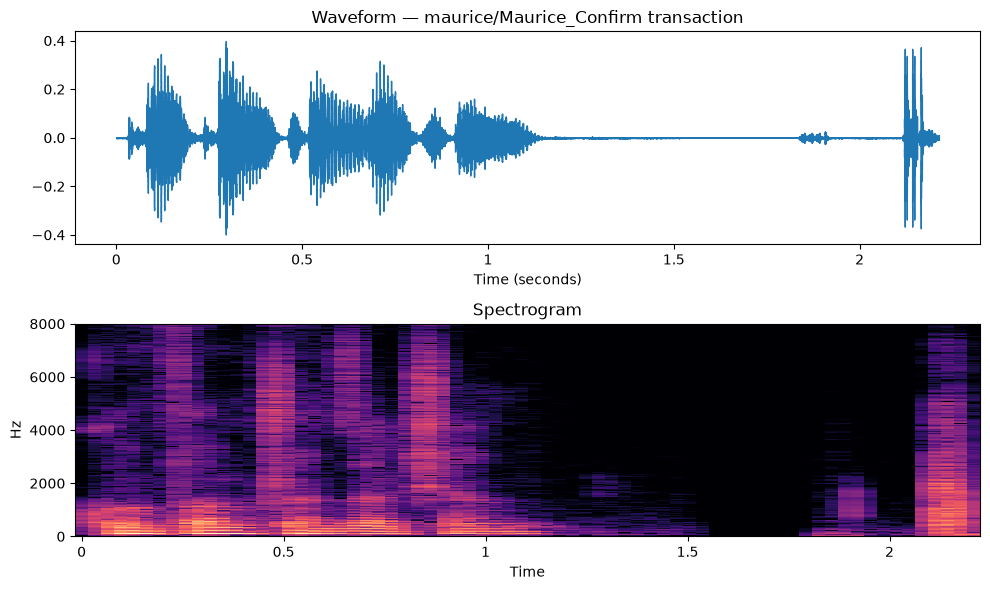

patrick / patrick/Patrick_Confirm_Transaction: 1.25s at 16000 Hz


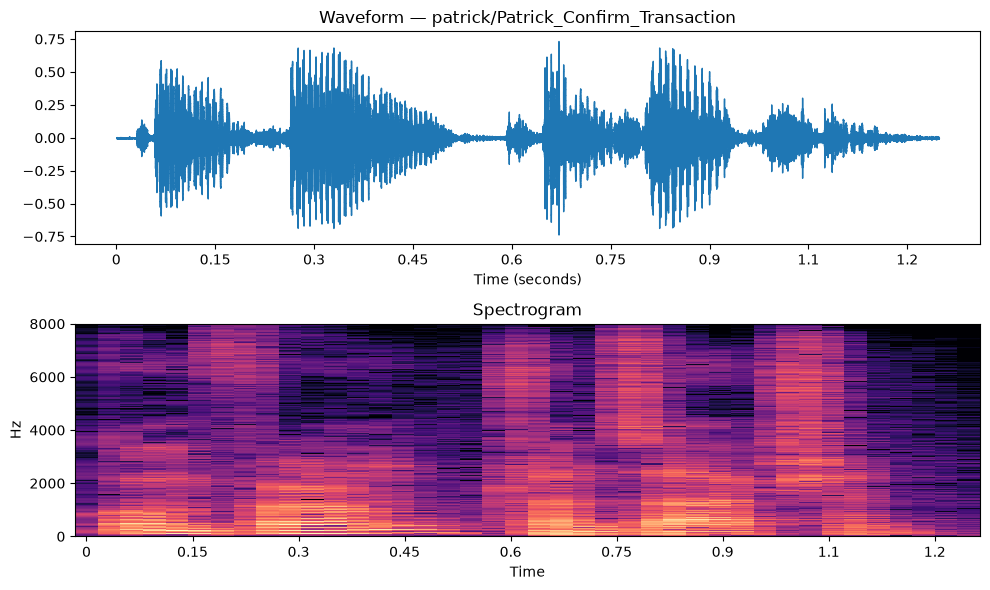

patrick / patrick/Patrick_Yes_Approve: 0.93s at 16000 Hz


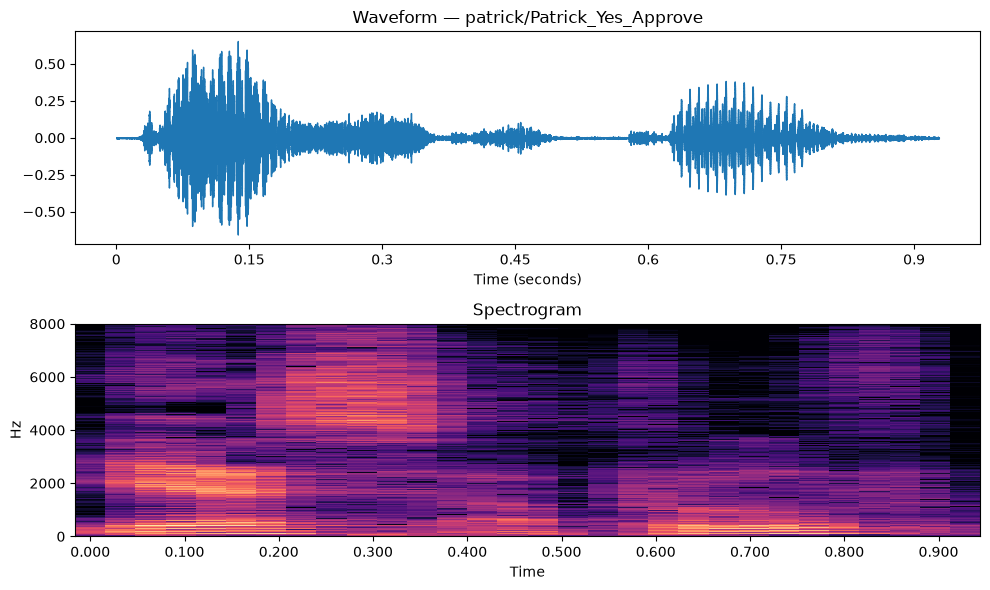

In [3]:
for recording in split_recordings:
    audio, sample_rate = load_voice_audio(recording["path"])
    duration = len(audio) / sample_rate
    print(f"{recording['user_id']} / {recording['source_id']}: {duration:.2f}s at {sample_rate} Hz")
    figure, axes = plt.subplots(2, 1, figsize=(10, 6))
    librosa.display.waveshow(audio, sr=sample_rate, ax=axes[0])
    axes[0].set(title=f"Waveform — {recording['source_id']}", xlabel="Time (seconds)")
    spectrum = librosa.amplitude_to_db(abs(librosa.stft(audio)), ref=np.max)
    librosa.display.specshow(spectrum, sr=sample_rate, x_axis="time", y_axis="hz", ax=axes[1])
    axes[1].set(title="Spectrogram")
    figure.tight_layout()
    plt.show()


### Short interpretation by member

- **Kudakwashe:** The 1.09 s and 1.63 s clips contain several strong speech-like bursts separated by quieter gaps. Both are short, so they provide limited voice material.
- **Larissa:** The 1.54 s approved clip has one dominant burst followed by smaller bursts; the 1.63 s confirmation clip has repeated bursts across the recording. Levels and pauses vary between the clips.
- **Maurice:** The 2.85 s and 2.21 s clips show most strong activity early, followed by long quiet regions and brief end transients. The plotted duration therefore includes substantial low-activity audio.
- **Patrick:** The 1.25 s and 0.93 s MP4 audio tracks contain several short bursts with quiet gaps. They are the shortest clips and offer limited material for stable speaker features.

These are observations of signal activity, not evidence that the speakers can be reliably distinguished.


## 3. Apply two augmentations per original

The original recording is split first; both augmented variants stay with that source and are used for training only when the source is in the training split. Validation and test metrics use original recordings only.

| Variant | Parameters |
|---|---|
| `pitch_shift_plus_1_semitone` | `librosa.effects.pitch_shift`, `n_steps=1.0`, `sr=16000` Hz. |
| `low_level_noise` | Gaussian noise with mean `0` and standard deviation `max(0.02 * RMS(original), 0.0001)`; clip waveform to `[-1.0, 1.0]`. Seed is `zlib.crc32(source_id)`. |

The original is unmodified. `audio_features.csv` records the exact parameters for each row in the JSON `augmentation_parameters` column.


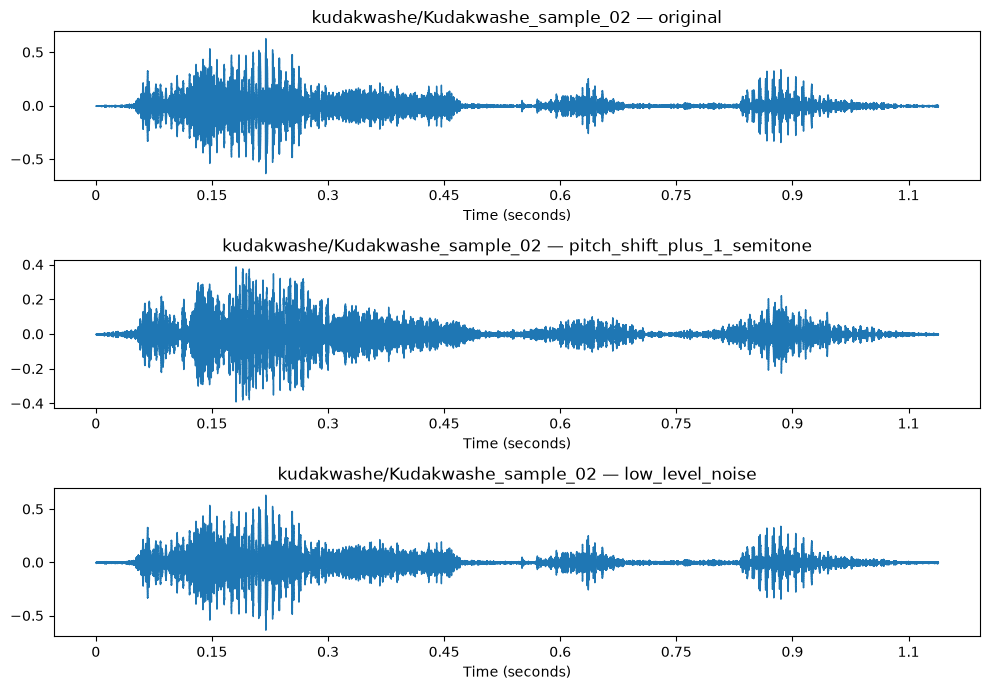

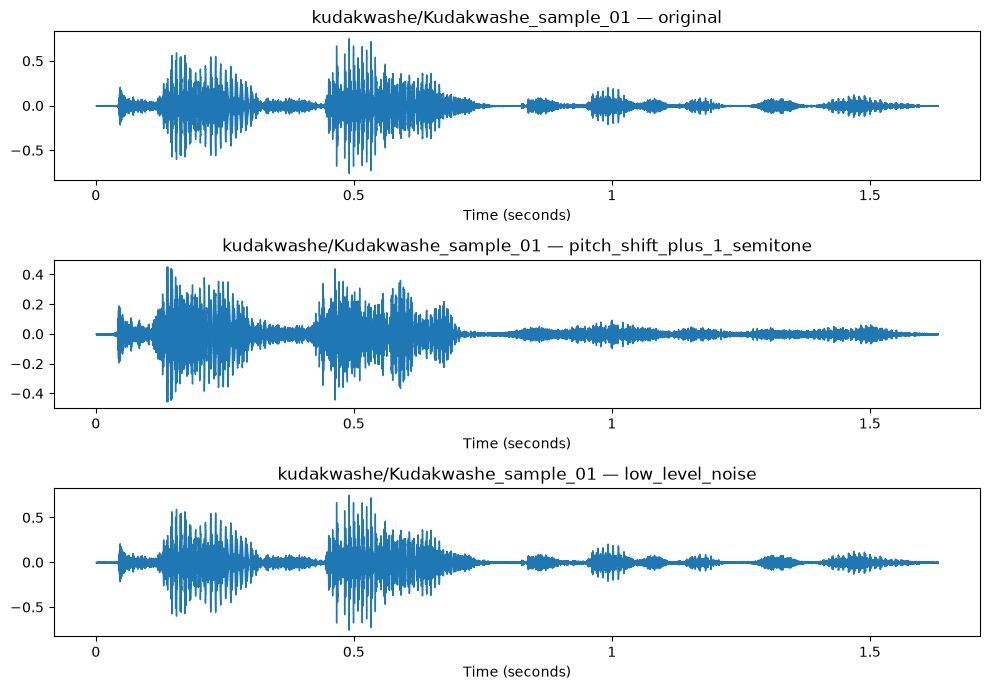

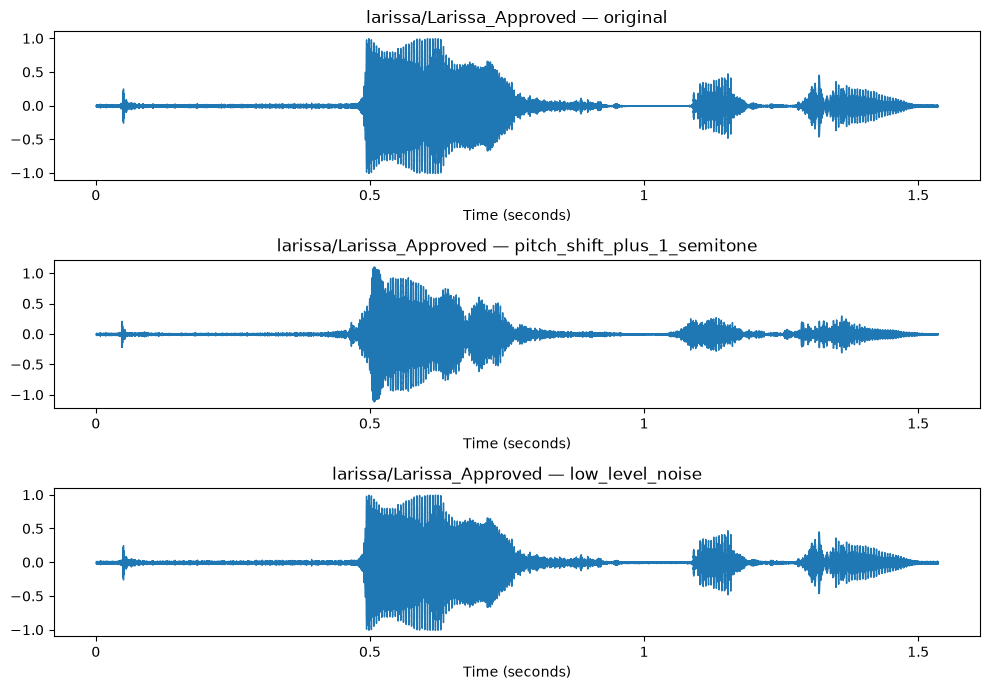

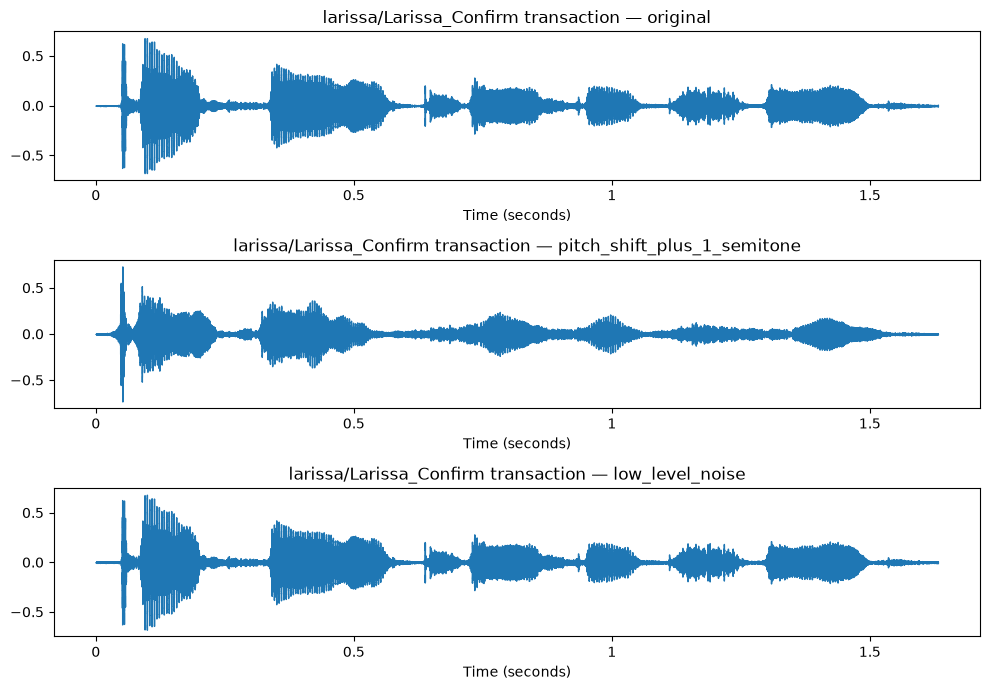

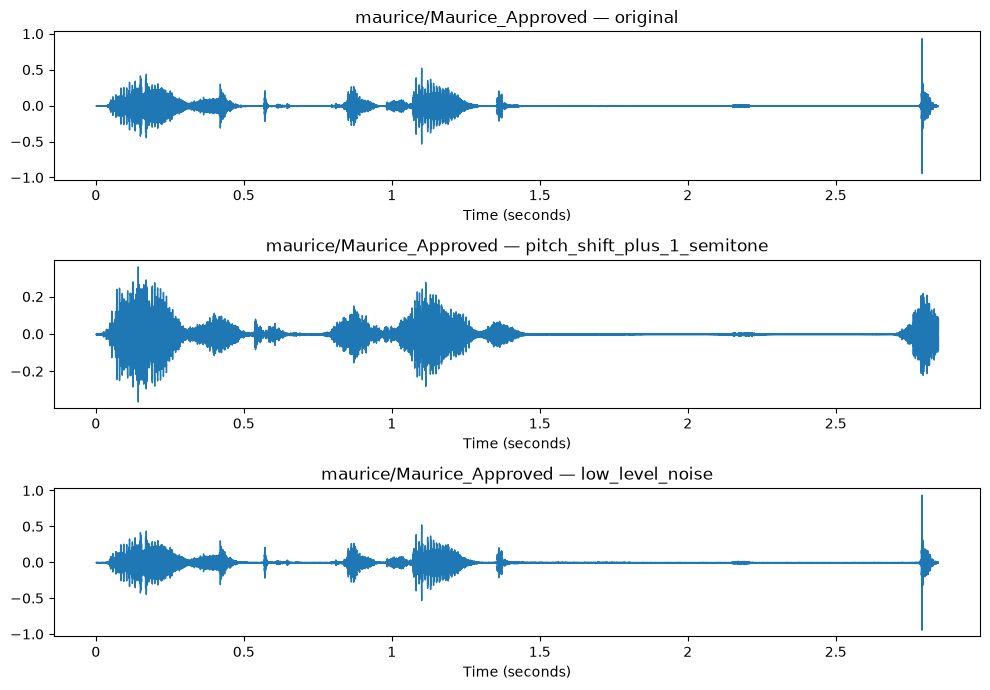

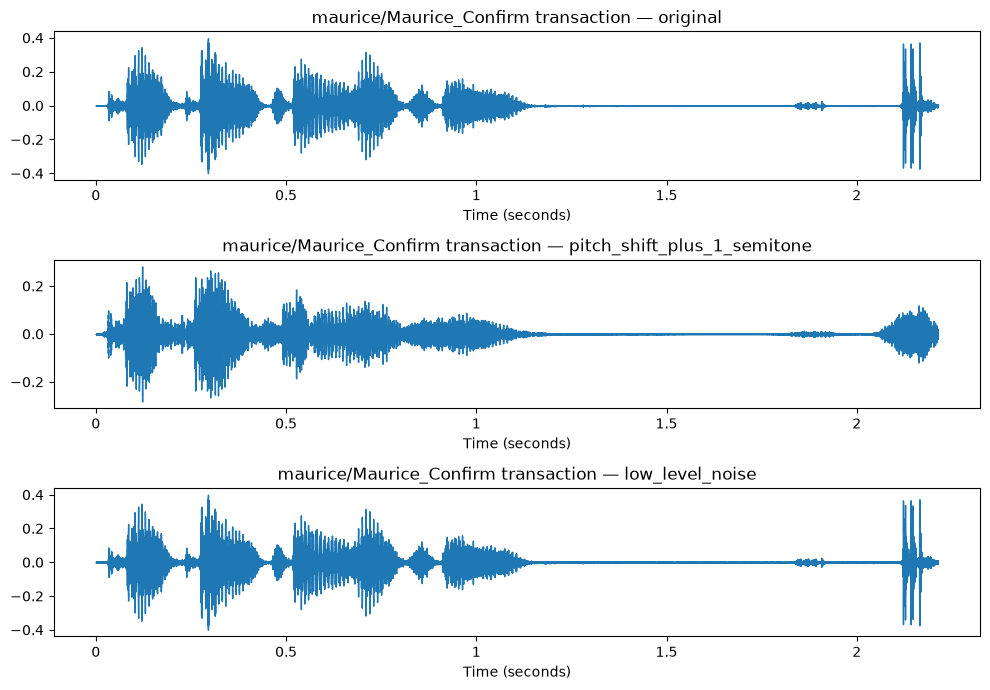

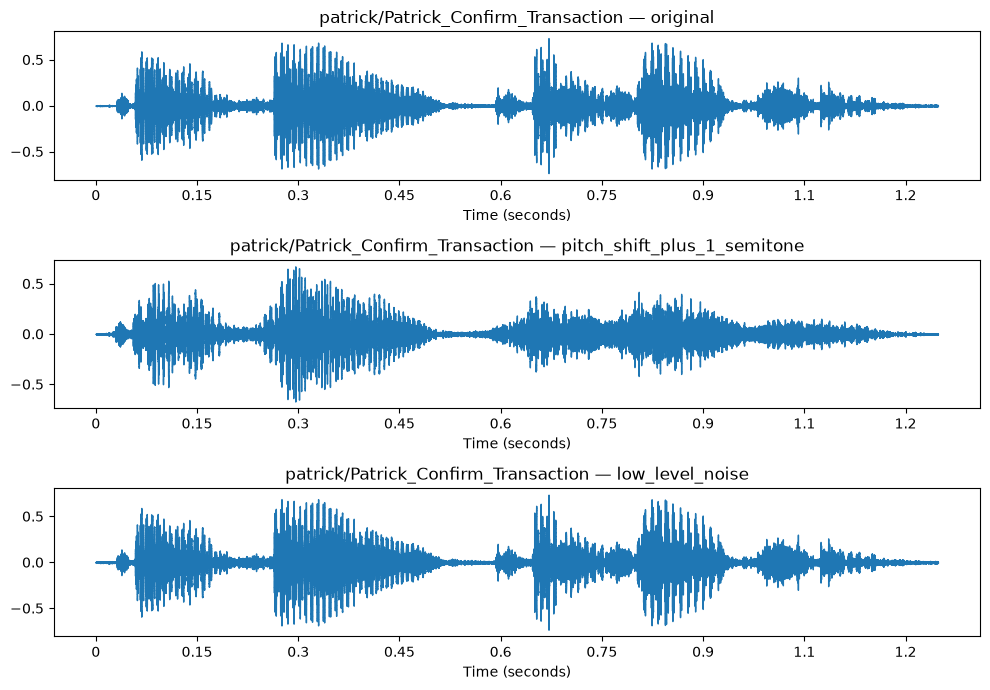

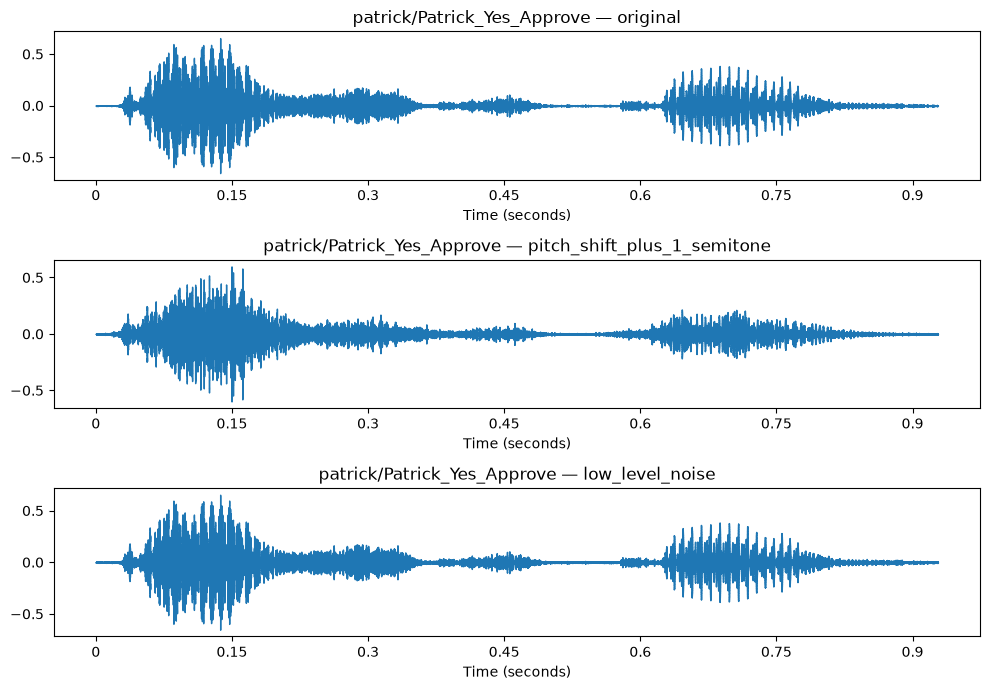

In [4]:
for recording in split_recordings:
    audio, sample_rate = load_voice_audio(recording["path"])
    seed = zlib.crc32(recording["source_id"].encode("utf-8"))
    variants = [("original", audio)] + augment_audio(audio, sample_rate, seed=seed)
    figure, axes = plt.subplots(len(variants), 1, figsize=(10, 7), squeeze=False)
    for axis, (name, waveform) in zip(axes[:, 0], variants):
        librosa.display.waveshow(waveform, sr=sample_rate, ax=axis)
        axis.set(title=f"{recording['source_id']} — {name}", xlabel="Time (seconds)")
    figure.tight_layout()
    plt.show()


## 4. Extract features, train, and evaluate

The shared extractor returns normalized pretrained speaker embeddings. The CSV also contains MFCC, spectral roll-off and RMS summaries for analysis. `augmentation_parameters` preserves augmentation settings but, like other provenance fields, is not a classifier input. Only embedding columns enter the classifier.


In [5]:
feature_table = build_feature_table(split_recordings)
print(f"Feature rows: {len(feature_table)}")
display(feature_table.groupby(["user_id", "split", "augmentation"], as_index=False).size())
result = train_voice_model(
    feature_table,
    MODELS / "voice_model.joblib",
    DATA / "processed" / "audio_features.csv",
    MODELS / "model_metadata.json",
)
print(f"Provisional validation threshold: {result['threshold']:.4f}")
print("Validation/calibration metrics:", result["validation_metrics"])
print("Complete independent test metrics (None unless every speaker is represented):", result["test_metrics"])
print(f"Saved voice model with {len(result['feature_columns'])} embedding features.")
print("Overall metadata status remains unchanged until all team models are trained and validated.")


C:\Users\pc\multimodal_authentication_preprocessing\.venv\Lib\site-packages\speechbrain\utils\parameter_transfer.py:234: UserWarning: Requested Pretrainer collection using symlinks on Windows. This might not work; see `LocalStrategy` documentation. Consider unsetting `collect_in` in Pretrainer to avoid symlinking altogether.
  warnings.warn(


Feature rows: 24


,user_id,split,augmentation,size
0,kudakwashe,train,low_level_noise,1
1,kudakwashe,train,original,1
2,kudakwashe,train,pitch_shift_plus_1_semitone,1
3,kudakwashe,validation,low_level_noise,1
4,kudakwashe,validation,original,1
5,kudakwashe,validation,pitch_shift_plus_1_semitone,1
6,larissa,train,low_level_noise,1
7,larissa,train,original,1
8,larissa,train,pitch_shift_plus_1_semitone,1
9,larissa,validation,low_level_noise,1


Provisional validation threshold: 0.2852
Validation/calibration metrics: {'accuracy': 0.75, 'macro_f1': 0.6666666666666666, 'log_loss': 1.125053817693952, 'false_accept_rate': 0.08333333333333333, 'false_reject_rate': 0.0, 'recordings': 4}
Complete independent test metrics (None unless every speaker is represented): None
Saved voice model with 192 embedding features.
Overall metadata status remains unchanged until all team models are trained and validated.


## 5. Unknown-speaker check

Only recordings placed in `data/raw/audio/unauthorized/` are scored as unknown people. Different enrolled-speaker claims are included in validation FAR/FRR calculations. Do not copy another enrolled member's audio into the unknown folder.

In [6]:
from feature_extraction import extract_voice_features

unauthorized_root = DATA / "raw" / "audio" / "unauthorized"
unauthorized_paths = sorted(
    path for path in unauthorized_root.rglob("*")
    if path.is_file() and path.suffix.lower() in {".flac", ".m4a", ".mp3", ".mp4", ".ogg", ".wav"}
)
unknown_false_accepts = 0
if not unauthorized_paths:
    print("No unknown-speaker recordings available; unknown-person FAR is not measured.")
else:
    for path in unauthorized_paths:
        probabilities = result["model"].predict_proba(extract_voice_features(path))
        best_index = int(probabilities[0].argmax())
        score = float(probabilities[0, best_index])
        decision = "accepted" if score >= result["threshold"] else "rejected"
        unknown_false_accepts += int(decision == "accepted")
        print(f"{path.name}: {decision} (best score={score:.4f})")
    unknown_far = unknown_false_accepts / len(unauthorized_paths)
    print(f"Unknown-speaker FAR: {unknown_far:.3f} ({unknown_false_accepts}/{len(unauthorized_paths)})")


No unknown-speaker recordings available; unknown-person FAR is not measured.
